# Module 7 — Two-Layer Neural Network with Backpropagation
**ECE 5831 · Fall 2026**

This notebook implements `TwoLayerNetBackprop` with NumPy and compares it with an
equivalent TensorFlow/Keras network on MNIST. Both approaches use backpropagation:
the NumPy model calculates the derivatives explicitly, while Keras calculates them
automatically. The supplied reference, *code_11_02_2026 - part1.docx*, is titled
“Compare Backpropagation vs Keras,” which identifies the two approaches used here.

The notebook includes the implementation, a numerical gradient check, actual
training logs, learning curves, final training and test accuracy, confusion
matrices, and example predictions. Run the cells from top to bottom.

## 1. Experimental setup

The two trainable layers are the hidden dense layer and the output dense layer;
the input is not counted as a trainable layer.

| Setting | Both approaches |
|:--|:--|
| Architecture | 784 inputs → 100 ReLU units → 10 softmax outputs |
| Dataset | Keras MNIST: 60,000 training images and 10,000 test images |
| Preprocessing | Flatten 28 × 28 images; divide pixel values by 255 |
| Initial weights | Same random normal weights, standard deviation 0.01 |
| Initial biases | Zeros |
| Loss | Mean categorical cross-entropy |
| Optimizer | Mini-batch SGD, learning rate 0.1, no momentum |
| Training | 10 epochs; batch size 64; same shuffle order each epoch |

All 60,000 training images are used in every epoch, including the final partial
batch. The test set is evaluated after training and is not used for updates,
early stopping, or hyperparameter selection. These settings follow the reference;
this is a comparison of implementations rather than a search for the best model.

**Running in VS Code or Jupyter:** choose a Python environment with TensorFlow,
NumPy, Matplotlib, and an IPython kernel. If a dependency is missing, uncomment
the installation line below, run it once, and restart the kernel. The first
`mnist.load_data()` call downloads the data if it is not already cached.

In [2]:
import os

# Set before importing TensorFlow. Small thread counts also suit this small model.
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "2")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")

import sys
import time
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
from IPython.display import Markdown, display

# Optional performance setting; it does not change the algorithm.
try:
    from threadpoolctl import threadpool_limits
    numpy_thread_limit = threadpool_limits(limits=1, user_api="blas")
except ImportError:
    pass

SEED = 42
SHUFFLE_SEED = 2026
INPUT_SIZE = 28 * 28
HIDDEN_SIZE = 100
OUTPUT_SIZE = 10
EPOCHS = 10
BATCH_SIZE = 64
EVAL_BATCH_SIZE = 1024
LEARNING_RATE = 0.1

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Platform:", platform.system(), platform.machine())
print("Devices:", [device.device_type for device in tf.config.list_physical_devices()])
print(f"Initialization seed = {SEED}; shuffle seed = {SHUFFLE_SEED}")

Python: 3.12.14
NumPy: 2.3.5
TensorFlow: 2.20.0
Keras: 3.15.1
Matplotlib: 3.10.8
Platform: Linux x86_64
Devices: ['CPU']
Initialization seed = 42; shuffle seed = 2026


## 2. Load and prepare MNIST

MNIST contains grayscale images of handwritten digits 0–9. The official Keras
loader returns the predefined training and test splits. Integer labels are kept
for reporting predictions, and one-hot labels are used for cross-entropy in both
models. No images are removed or replaced with another dataset.

Source: [Keras MNIST dataset documentation](https://keras.io/api/datasets/mnist/).

In [3]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Original shapes:")
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test :", X_test.shape, " y_test :", y_test.shape)

assert X_train.shape == (60000, 28, 28)
assert X_test.shape == (10000, 28, 28)
assert y_train.shape == (60000,) and y_test.shape == (10000,)

X_train = X_train.reshape(len(X_train), INPUT_SIZE).astype(np.float32) / 255.0
X_test = X_test.reshape(len(X_test), INPUT_SIZE).astype(np.float32) / 255.0
y_train_onehot = np.eye(OUTPUT_SIZE, dtype=np.float32)[y_train]
y_test_onehot = np.eye(OUTPUT_SIZE, dtype=np.float32)[y_test]

assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert X_train.min() >= 0 and X_train.max() <= 1
assert X_test.min() >= 0 and X_test.max() <= 1
np.testing.assert_allclose(y_train_onehot.sum(axis=1), 1)
np.testing.assert_array_equal(y_train_onehot.argmax(axis=1), y_train)

print("\nPrepared shapes:")
print("X_train:", X_train.shape, X_train.dtype)
print("X_test :", X_test.shape, X_test.dtype)
print("One-hot train/test:", y_train_onehot.shape, y_test_onehot.shape)
print("Pixel range:", float(X_train.min()), "to", float(X_train.max()))
print("Training class counts:", np.bincount(y_train, minlength=10))
print("Test class counts:    ", np.bincount(y_test, minlength=10))

Original shapes:
X_train: (60000, 28, 28)  y_train: (60000,)
X_test : (10000, 28, 28)  y_test : (10000,)

Prepared shapes:
X_train: (60000, 784) float32
X_test : (10000, 784) float32
One-hot train/test: (60000, 10) (10000, 10)
Pixel range: 0.0 to 1.0
Training class counts: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
Test class counts:     [ 980 1135 1032 1010  982  892  958 1028  974 1009]


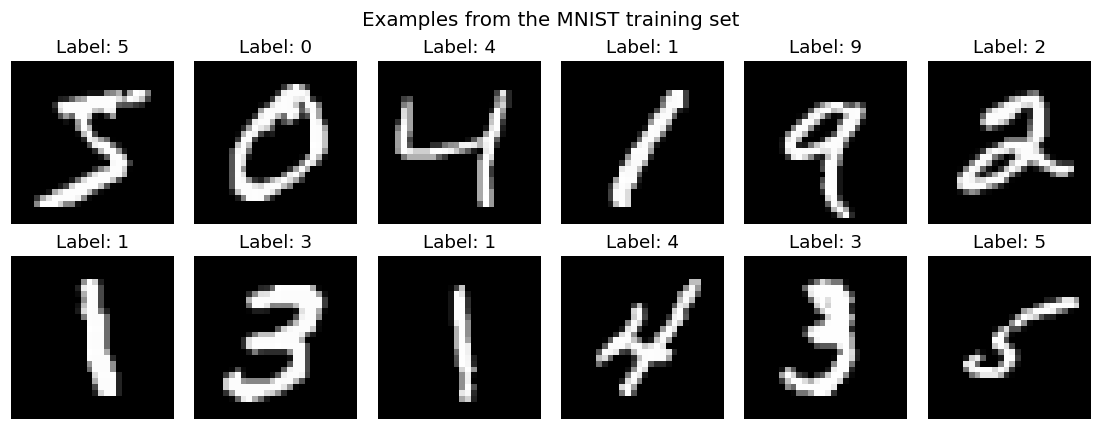

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(10, 3.8), constrained_layout=True)
for index, ax in enumerate(axes.flat):
    ax.imshow(X_train[index].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {y_train[index]}")
    ax.axis("off")
fig.suptitle("Examples from the MNIST training set", fontsize=13)
plt.show()

## 3. Forward propagation and backpropagation

For a mini-batch $X\in\mathbb{R}^{N\times784}$, the forward pass is

\[
A_1=XW_1+b_1,\qquad H=\operatorname{ReLU}(A_1),\qquad
A_2=HW_2+b_2,\qquad P=\operatorname{softmax}(A_2).
\]

With one-hot targets $Y$, the mean cross-entropy is

\[
L=-\frac{1}{N}\sum_{i=1}^{N}\sum_{c=1}^{10}Y_{ic}\log P_{ic}.
\]

The output derivative simplifies to $D_2=(P-Y)/N$. Applying the chain rule gives

\[
\begin{aligned}
\nabla_{W_2}L &= H^\top D_2,&
\nabla_{b_2}L &= \sum_i D_{2,i},\\
D_1 &= (D_2W_2^\top)\odot\mathbf{1}[A_1>0],\\
\nabla_{W_1}L &= X^\top D_1,&
\nabla_{b_1}L &= \sum_i D_{1,i}.
\end{aligned}
\]

SGD updates every parameter using $\theta\leftarrow\theta-\eta\nabla_\theta L$.
The code subtracts the maximum logit before softmax and calculates log-softmax
directly for the loss. This avoids overflow and avoids taking the logarithm of a
probability that has rounded to zero. ReLU's derivative at zero is defined as zero.

In [5]:
class TwoLayerNetBackprop:
    """Two dense layers with a ReLU hidden layer and softmax output.

    Training uses only NumPy. Loss/backward/evaluate expect one-hot targets
    with shape (batch_size, output_size). forward/predict always return a
    2-D probability array, including for a single flattened image.
    """

    def __init__(self, input_size=784, hidden_size=100, output_size=10,
                 weight_init_std=0.01, seed=42, dtype=np.float32):
        self.input_size = input_size
        self.output_size = output_size
        self.dtype = np.dtype(dtype)
        rng = np.random.default_rng(seed)
        self.params = {
            "w1": (weight_init_std * rng.standard_normal(
                (input_size, hidden_size))).astype(self.dtype),
            "b1": np.zeros(hidden_size, dtype=self.dtype),
            "w2": (weight_init_std * rng.standard_normal(
                (hidden_size, output_size))).astype(self.dtype),
            "b2": np.zeros(output_size, dtype=self.dtype),
        }
        self.cache = None

    @staticmethod
    def relu(x):
        return np.maximum(0, x)

    @staticmethod
    def relu_grad(x):
        return (x > 0).astype(x.dtype)

    @staticmethod
    def softmax(logits):
        shifted = logits - np.max(logits, axis=-1, keepdims=True)
        exp_values = np.exp(shifted)
        return exp_values / np.sum(exp_values, axis=-1, keepdims=True)

    def _onehot_targets(self, y, n_samples):
        y = np.atleast_2d(np.asarray(y, dtype=self.dtype))
        if y.shape != (n_samples, self.output_size):
            raise ValueError("Use one-hot targets of shape (batch_size, output_size).")
        return y

    def forward(self, x):
        """Calculate probabilities and cache intermediate values for backward."""
        x = np.atleast_2d(np.asarray(x, dtype=self.dtype))
        if x.shape[1] != self.input_size:
            raise ValueError(f"Each image must have {self.input_size} features.")
        a1 = x @ self.params["w1"] + self.params["b1"]
        h = self.relu(a1)
        logits = h @ self.params["w2"] + self.params["b2"]
        probabilities = self.softmax(logits)
        self.cache = {
            "x": x, "a1": a1, "h": h,
            "logits": logits, "probabilities": probabilities,
        }
        return probabilities

    def predict(self, x):
        """Return probabilities; use argmax(axis=1) to obtain digit labels."""
        return self.forward(x)

    def loss(self, x, y):
        """Mean cross-entropy, computed stably from the output logits."""
        probabilities = self.forward(x)
        y = self._onehot_targets(y, len(probabilities))
        logits = self.cache["logits"]
        shifted = logits - np.max(logits, axis=1, keepdims=True)
        log_probabilities = shifted - np.log(
            np.sum(np.exp(shifted), axis=1, keepdims=True)
        )
        return float(-np.sum(y * log_probabilities) / len(y))

    def backward(self, y):
        """Use the most recent forward pass to compute all four gradients."""
        if self.cache is None:
            raise RuntimeError("Call forward(x) before backward(y).")
        x = self.cache["x"]
        a1 = self.cache["a1"]
        h = self.cache["h"]
        probabilities = self.cache["probabilities"]
        y = self._onehot_targets(y, len(x))

        # Softmax + mean cross-entropy. len(x) handles a partial last batch.
        d2 = (probabilities - y) / len(x)
        dw2 = h.T @ d2
        db2 = np.sum(d2, axis=0)

        # Propagate through the second affine layer, then through ReLU.
        dh = d2 @ self.params["w2"].T
        d1 = dh * self.relu_grad(a1)
        dw1 = x.T @ d1
        db1 = np.sum(d1, axis=0)

        return {"w1": dw1, "b1": db1, "w2": dw2, "b2": db2}

    def gradient(self, x, y):
        """Run forward propagation and backpropagation on one mini-batch."""
        self.forward(x)
        return self.backward(y)

    def evaluate(self, x, y, batch_size=1024):
        """Return loss, accuracy, and correct count without updating weights."""
        x = np.atleast_2d(np.asarray(x, dtype=self.dtype))
        y = self._onehot_targets(y, len(x))
        if len(x) == 0 or batch_size <= 0:
            raise ValueError("Evaluation needs samples and a positive batch size.")
        loss_sum = 0.0
        correct = 0
        for start in range(0, len(x), batch_size):
            xb = x[start:start + batch_size]
            yb = y[start:start + batch_size]
            loss_sum += self.loss(xb, yb) * len(xb)
            predictions = self.cache["probabilities"].argmax(axis=1)
            correct += int(np.sum(predictions == yb.argmax(axis=1)))
        return {"loss": loss_sum / len(x),
                "accuracy": correct / len(x), "correct": correct}

    def accuracy(self, x, y, batch_size=1024):
        return self.evaluate(x, y, batch_size)["accuracy"]

### Check the gradients before training

For a small 4 → 5 → 3 network, each analytical derivative is compared with the
central finite-difference approximation

\[
\frac{\partial L}{\partial\theta_j}\approx
\frac{L(\theta_j+\varepsilon)-L(\theta_j-\varepsilon)}{2\varepsilon}.
\]

This check uses `float64` and verifies every parameter of the small network.
The test inputs stay away from the point where ReLU changes slope. Numerical
derivatives are used only for verification; MNIST training uses backpropagation.

In [6]:
check_rng = np.random.default_rng(7)
check_net = TwoLayerNetBackprop(4, 5, 3, weight_init_std=0.1,
                              seed=19, dtype=np.float64)
check_net.params["b1"][:] = 0.2
check_x = check_rng.normal(size=(6, 4))
check_y = np.eye(3, dtype=np.float64)[np.array([0, 1, 2, 1, 0, 2])]
analytical = check_net.gradient(check_x, check_y)
epsilon = 1e-5
assert np.min(np.abs(check_net.cache["a1"])) > 100 * epsilon

print(f"{'Parameter':<12} {'Max absolute error':>20} {'Relative L2 error':>20}")
for name, parameter in check_net.params.items():
    numerical = np.zeros_like(parameter)
    for index in np.ndindex(parameter.shape):
        original = parameter[index]
        parameter[index] = original + epsilon
        loss_plus = check_net.loss(check_x, check_y)
        parameter[index] = original - epsilon
        loss_minus = check_net.loss(check_x, check_y)
        parameter[index] = original
        numerical[index] = (loss_plus - loss_minus) / (2 * epsilon)
    absolute_error = np.max(np.abs(analytical[name] - numerical))
    relative_error = np.linalg.norm(analytical[name] - numerical) / (
        np.linalg.norm(analytical[name]) + np.linalg.norm(numerical) + 1e-12
    )
    np.testing.assert_allclose(analytical[name], numerical, rtol=1e-4, atol=1e-7)
    print(f"{name:<12} {absolute_error:>20.3e} {relative_error:>20.3e}")

probabilities = check_net.predict(check_x)
assert probabilities.shape == (6, 3)
np.testing.assert_allclose(probabilities.sum(axis=1), 1.0, atol=1e-12)
print("PASS: all analytical gradients match numerical derivatives.")

Parameter      Max absolute error    Relative L2 error
w1                      1.391e-11            1.322e-10
b1                      1.287e-11            6.017e-10
w2                      1.341e-11            1.766e-10
b2                      7.885e-12            2.132e-10
PASS: all analytical gradients match numerical derivatives.


## 4. Create equivalent NumPy and Keras models

The Keras model uses the same layer sizes, activations, loss, and SGD update.
Its initial weights are copied from the untrained NumPy model so initialization
is identical. A fixed list of epoch permutations also makes the mini-batches
identical. Both models have **79,510 trainable parameters**.

Keras documentation: [Dense layer](https://keras.io/api/layers/core_layers/dense/)
and [SGD](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/SGD).

In [7]:
network = TwoLayerNetBackprop(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE, seed=SEED)
initial_weights = [network.params[name].copy() for name in ("w1", "b1", "w2", "b2")]

keras_model = keras.Sequential([
    keras.Input(shape=(INPUT_SIZE,)),
    layers.Dense(HIDDEN_SIZE, activation="relu", name="hidden"),
    layers.Dense(OUTPUT_SIZE, activation="softmax", name="output"),
], name="two_layer_keras")
keras_model.set_weights(initial_weights)
keras_model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=LEARNING_RATE, momentum=0.0),
    loss=keras.losses.CategoricalCrossentropy(),
    metrics=[keras.metrics.CategoricalAccuracy(name="accuracy")],
    jit_compile=False,
)

np.testing.assert_allclose(
    network.predict(X_train[:32]),
    keras_model(X_train[:32], training=False).numpy(),
    rtol=1e-5, atol=1e-7,
)
print("PASS: both models give matching predictions before training.")
print("NumPy parameter count:", sum(p.size for p in network.params.values()))
keras_model.summary()

shuffle_rng = np.random.default_rng(SHUFFLE_SEED)
epoch_orders = [shuffle_rng.permutation(len(X_train)) for _ in range(EPOCHS)]

# Explicit tf.data options keep thread use small and preserve the chosen order.
dataset_options = tf.data.Options()
dataset_options.experimental_deterministic = True
dataset_options.threading.private_threadpool_size = 1
dataset_options.threading.max_intra_op_parallelism = 1

def make_dataset(x, y, batch_size):
    return (tf.data.Dataset.from_tensor_slices((x, y))
            .batch(batch_size, drop_remainder=False)
            .with_options(dataset_options))

keras_train_eval_data = make_dataset(X_train, y_train_onehot, EVAL_BATCH_SIZE)

PASS: both models give matching predictions before training.
NumPy parameter count: 79510
Model: "two_layer_keras"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden (Dense)                  │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 79,510 (310.59 KB)
 Trainable params: 79,510 (310.59 KB)
 Non-trainable params: 0 (0.00 B)


## 5. Approach 1 — Train the NumPy model with manual backpropagation

For each mini-batch, `gradient()` runs the forward pass and the backward pass.
The following loop updates the weights and biases explicitly. At the end of
each epoch, the loss and accuracy are measured on the complete training set
using that epoch's final weights.

In [8]:
initial_train = network.evaluate(X_train, y_train_onehot, EVAL_BATCH_SIZE)
numpy_history = {"loss": [], "accuracy": []}
print(f"Before training | Loss: {initial_train['loss']:.4f} | "
      f"Training accuracy: {initial_train['accuracy']:.2%}")

started = time.perf_counter()
for epoch, order in enumerate(epoch_orders, start=1):
    for start in range(0, len(X_train), BATCH_SIZE):
        indices = order[start:start + BATCH_SIZE]
        x_batch = X_train[indices]
        y_batch = y_train_onehot[indices]
        gradients = network.gradient(x_batch, y_batch)
        for name in network.params:
            network.params[name] -= LEARNING_RATE * gradients[name]

    metrics = network.evaluate(X_train, y_train_onehot, EVAL_BATCH_SIZE)
    numpy_history["loss"].append(metrics["loss"])
    numpy_history["accuracy"].append(metrics["accuracy"])
    print(f"Epoch {epoch:2d}/{EPOCHS} | Loss: {metrics['loss']:.4f} | "
          f"Training accuracy: {metrics['accuracy']:.2%}")

numpy_training_seconds = time.perf_counter() - started
print(f"NumPy training loop time: {numpy_training_seconds:.2f} seconds")
assert numpy_history["loss"][-1] < initial_train["loss"]
assert numpy_history["accuracy"][-1] > initial_train["accuracy"]

Before training | Loss: 2.3022 | Training accuracy: 12.04%
Epoch  1/10 | Loss: 0.2920 | Training accuracy: 91.84%
Epoch  2/10 | Loss: 0.2092 | Training accuracy: 94.00%
Epoch  3/10 | Loss: 0.1633 | Training accuracy: 95.30%
Epoch  4/10 | Loss: 0.1276 | Training accuracy: 96.40%
Epoch  5/10 | Loss: 0.1156 | Training accuracy: 96.69%
Epoch  6/10 | Loss: 0.0976 | Training accuracy: 97.21%
Epoch  7/10 | Loss: 0.0903 | Training accuracy: 97.36%
Epoch  8/10 | Loss: 0.0794 | Training accuracy: 97.78%
Epoch  9/10 | Loss: 0.0690 | Training accuracy: 98.06%
Epoch 10/10 | Loss: 0.0628 | Training accuracy: 98.26%
NumPy training loop time: 5.03 seconds


## 6. Approach 2 — Train the equivalent Keras model

Keras performs differentiation and parameter updates inside `fit()`. Each call
uses the same epoch permutation as the NumPy loop; the dataset is already
batched in that order. The model and optimizer persist across all ten calls.

The metrics below come from `evaluate()` **after** each epoch. Keras's running
metrics inside `fit()` mix predictions from changing weights; using explicit
end-of-epoch evaluation makes these curves comparable with the NumPy curves.

In [9]:
keras_history = {"loss": [], "accuracy": []}
keras_initial_train = keras_model.evaluate(
    keras_train_eval_data, verbose=0, return_dict=True
)
print(f"Before training | Loss: {keras_initial_train['loss']:.4f} | "
      f"Training accuracy: {keras_initial_train['accuracy']:.2%}")

started = time.perf_counter()
for epoch, order in enumerate(epoch_orders, start=1):
    epoch_data = make_dataset(X_train[order], y_train_onehot[order], BATCH_SIZE)
    keras_model.fit(epoch_data, epochs=1, verbose=0, shuffle=False)
    metrics = keras_model.evaluate(keras_train_eval_data, verbose=0, return_dict=True)
    keras_history["loss"].append(float(metrics["loss"]))
    keras_history["accuracy"].append(float(metrics["accuracy"]))
    print(f"Epoch {epoch:2d}/{EPOCHS} | Loss: {metrics['loss']:.4f} | "
          f"Training accuracy: {metrics['accuracy']:.2%}")

keras_training_seconds = time.perf_counter() - started
print(f"Keras training loop time: {keras_training_seconds:.2f} seconds")
assert keras_history["loss"][-1] < keras_initial_train["loss"]
assert keras_history["accuracy"][-1] > keras_initial_train["accuracy"]

Before training | Loss: 2.3022 | Training accuracy: 12.04%
Epoch  1/10 | Loss: 0.2920 | Training accuracy: 91.84%
Epoch  2/10 | Loss: 0.2093 | Training accuracy: 93.99%
Epoch  3/10 | Loss: 0.1634 | Training accuracy: 95.29%
Epoch  4/10 | Loss: 0.1275 | Training accuracy: 96.39%
Epoch  5/10 | Loss: 0.1162 | Training accuracy: 96.69%
Epoch  6/10 | Loss: 0.0976 | Training accuracy: 97.24%
Epoch  7/10 | Loss: 0.0900 | Training accuracy: 97.38%
Epoch  8/10 | Loss: 0.0791 | Training accuracy: 97.83%
Epoch  9/10 | Loss: 0.0689 | Training accuracy: 98.07%
Epoch 10/10 | Loss: 0.0627 | Training accuracy: 98.28%
Keras training loop time: 15.22 seconds


## 7. Compare the learning curves

Each point represents an evaluation of all 60,000 training examples after an
epoch, with no parameter updates during evaluation. Both implementations use
the same optimization procedure, so similar curves are expected. Small
differences can arise from floating-point arithmetic and execution libraries.

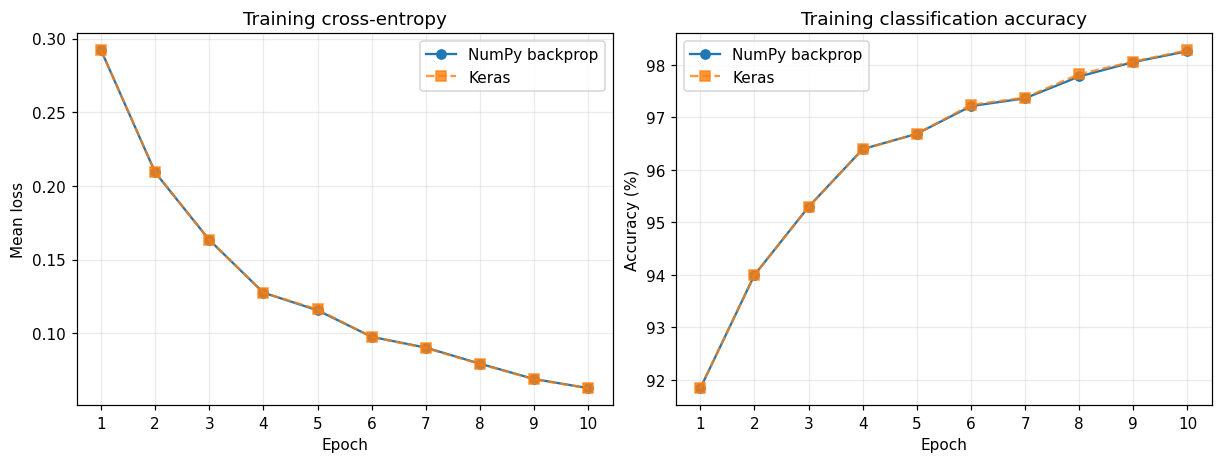

In [10]:
epochs_axis = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), constrained_layout=True)

axes[0].plot(epochs_axis, numpy_history["loss"], "o-", label="NumPy backprop")
axes[0].plot(epochs_axis, keras_history["loss"], "s--", label="Keras", alpha=0.8)
axes[0].set(title="Training cross-entropy", xlabel="Epoch", ylabel="Mean loss")

axes[1].plot(epochs_axis, 100 * np.array(numpy_history["accuracy"]),
             "o-", label="NumPy backprop")
axes[1].plot(epochs_axis, 100 * np.array(keras_history["accuracy"]),
             "s--", label="Keras", alpha=0.8)
axes[1].set(title="Training classification accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
for ax in axes:
    ax.set_xticks(epochs_axis)
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## 8. Final training and test results

Classification accuracy is the number of correctly predicted labels divided by
the number of examples. The predicted label is the output with the highest
probability. Both trained models are now evaluated on the full training set and
the same untouched 10,000-image test set.

The tables below are generated from this notebook's execution. Times measure
the training loops, including shuffling/dataset preparation and full training-set
evaluation after each epoch; the Keras time also includes its first training
compilation. They are specific to this runtime and are not a general speed benchmark.

In [11]:
numpy_train_results = network.evaluate(X_train, y_train_onehot, EVAL_BATCH_SIZE)
numpy_test_results = network.evaluate(X_test, y_test_onehot, EVAL_BATCH_SIZE)
keras_train_results = keras_model.evaluate(
    keras_train_eval_data, verbose=0, return_dict=True
)
keras_test_results = keras_model.evaluate(
    make_dataset(X_test, y_test_onehot, EVAL_BATCH_SIZE),
    verbose=0, return_dict=True,
)

# Integer correct counts also verify the reported accuracy independently.
numpy_test_predictions = np.concatenate([
    network.predict(X_test[start:start + EVAL_BATCH_SIZE]).argmax(axis=1)
    for start in range(0, len(X_test), EVAL_BATCH_SIZE)
])
keras_test_predictions = np.concatenate([
    keras_model(X_test[start:start + EVAL_BATCH_SIZE], training=False)
    .numpy().argmax(axis=1)
    for start in range(0, len(X_test), EVAL_BATCH_SIZE)
])
numpy_test_correct = int(np.sum(numpy_test_predictions == y_test))
keras_test_correct = int(np.sum(keras_test_predictions == y_test))
assert numpy_test_correct == numpy_test_results["correct"]
np.testing.assert_allclose(keras_test_correct / len(y_test),
                           keras_test_results["accuracy"], atol=1e-7, rtol=0)

results_table = "| Approach | Training loss | Training accuracy | Test loss | Test accuracy | Correct test predictions |\n"
results_table += "|:--|--:|--:|--:|--:|--:|\n"
results_table += (
    f"| NumPy `TwoLayerNetBackprop` | {numpy_train_results['loss']:.4f} | "
    f"{numpy_train_results['accuracy']:.2%} | {numpy_test_results['loss']:.4f} | "
    f"{numpy_test_correct / len(y_test):.2%} | {numpy_test_correct:,} / {len(y_test):,} |\n"
    f"| Keras | {keras_train_results['loss']:.4f} | "
    f"{keras_train_results['accuracy']:.2%} | {keras_test_results['loss']:.4f} | "
    f"{keras_test_correct / len(y_test):.2%} | {keras_test_correct:,} / {len(y_test):,} |"
)
display(Markdown(results_table))
print(f"NumPy training loop: {numpy_training_seconds:.2f} s")
print(f"Keras training loop: {keras_training_seconds:.2f} s")
print(f"Final-batch size: {len(X_train) % BATCH_SIZE}; "
      f"updates per epoch: {(len(X_train) + BATCH_SIZE - 1) // BATCH_SIZE}")

NumPy training loop: 5.03 s
Keras training loop: 15.22 s
Final-batch size: 32; updates per epoch: 938


| Approach | Training loss | Training accuracy | Test loss | Test accuracy | Correct test predictions |
|:--|--:|--:|--:|--:|--:|
| NumPy `TwoLayerNetBackprop` | 0.0628 | 98.26% | 0.0902 | 97.40% | 9,740 / 10,000 |
| Keras | 0.0627 | 98.28% | 0.0904 | 97.36% | 9,736 / 10,000 |

### Confusion matrices

Rows are true digits and columns are predicted digits. Diagonal entries are
correct predictions; off-diagonal entries show which digits were confused.
Both matrices use the same color scale and contain all 10,000 test examples.

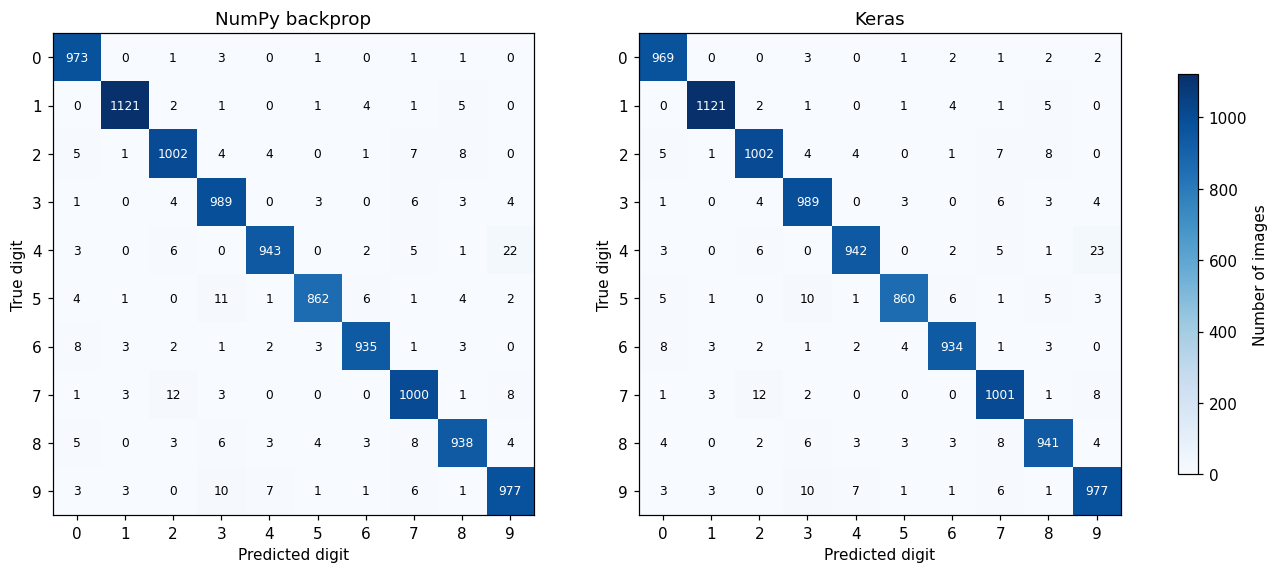

In [12]:
def confusion_matrix(true_labels, predicted_labels, n_classes=10):
    matrix = np.zeros((n_classes, n_classes), dtype=np.int64)
    np.add.at(matrix, (true_labels, predicted_labels), 1)
    return matrix

numpy_cm = confusion_matrix(y_test, numpy_test_predictions)
keras_cm = confusion_matrix(y_test, keras_test_predictions)
assert numpy_cm.sum() == keras_cm.sum() == len(y_test)
assert np.trace(numpy_cm) == numpy_test_correct
assert np.trace(keras_cm) == keras_test_correct

fig, axes = plt.subplots(1, 2, figsize=(12, 5.1), constrained_layout=True)
max_count = max(numpy_cm.max(), keras_cm.max())
for ax, matrix, title in zip(axes, [numpy_cm, keras_cm], ["NumPy backprop", "Keras"]):
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=max_count)
    for row in range(10):
        for col in range(10):
            ax.text(col, row, str(matrix[row, col]), ha="center", va="center",
                    fontsize=8, color="white" if matrix[row, col] > max_count / 2 else "black")
    ax.set(title=title, xlabel="Predicted digit", ylabel="True digit",
           xticks=np.arange(10), yticks=np.arange(10))
fig.colorbar(image, ax=axes, shrink=0.83, label="Number of images")
plt.show()

### Example predictions on the test set

The first twelve test images are shown in their original order. Each title gives
the true label and both predictions. A green title means both models are correct;
a red title means at least one model is incorrect.

Single test case — image index 10
True digit: 0
NumPy prediction: 0
Keras prediction: 0


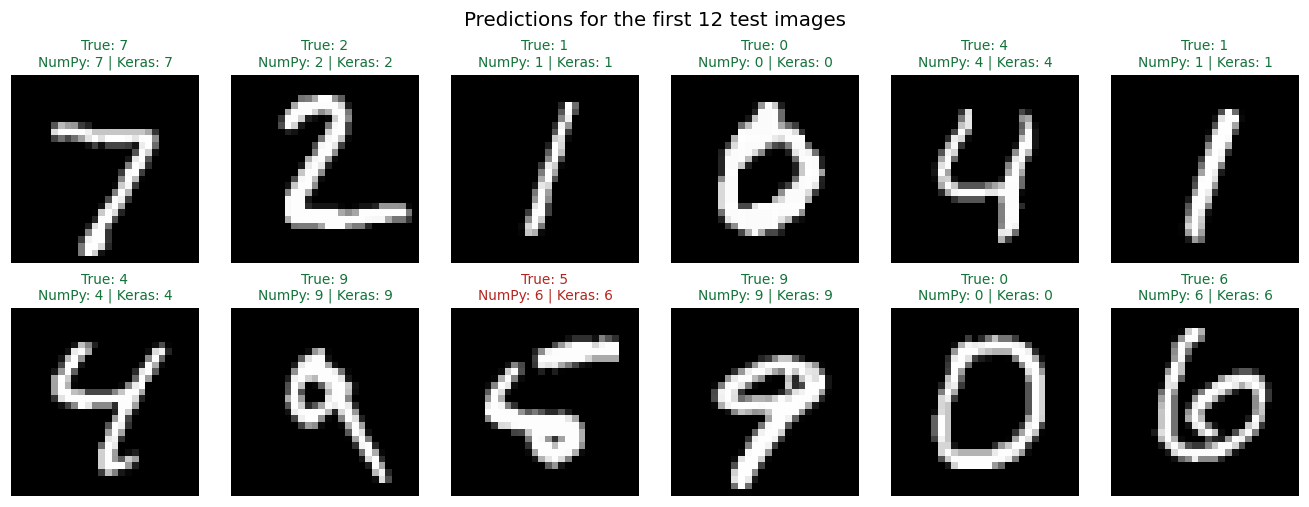

In [13]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5), constrained_layout=True)
for index, ax in enumerate(axes.flat):
    actual = int(y_test[index])
    numpy_prediction = int(numpy_test_predictions[index])
    keras_prediction = int(keras_test_predictions[index])
    both_correct = numpy_prediction == actual and keras_prediction == actual
    ax.imshow(X_test[index].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"True: {actual}\nNumPy: {numpy_prediction} | Keras: {keras_prediction}",
                 color="#13733a" if both_correct else "#b3261e", fontsize=9)
    ax.axis("off")
fig.suptitle("Predictions for the first 12 test images", fontsize=13)
plt.show()

index = 10
print(f"Single test case — image index {index}")
print(f"True digit: {y_test[index]}")
print(f"NumPy prediction: {numpy_test_predictions[index]}")
print(f"Keras prediction: {keras_test_predictions[index]}")

## 9. Conclusions

The following summary is computed from the results above, so it updates if the
notebook is rerun. A difference from a later run can reflect library versions,
hardware, and floating-point arithmetic even with fixed seeds.

In [14]:
numpy_test_accuracy = numpy_test_correct / len(y_test)
keras_test_accuracy = keras_test_correct / len(y_test)
test_gap_pp = 100 * abs(numpy_test_accuracy - keras_test_accuracy)
numpy_generalization_gap_pp = 100 * (numpy_train_results["accuracy"] - numpy_test_accuracy)
keras_generalization_gap_pp = 100 * (keras_train_results["accuracy"] - keras_test_accuracy)

summary = f"""
`TwoLayerNetBackprop` trained successfully: its training loss decreased from
**{initial_train['loss']:.4f}** to **{numpy_train_results['loss']:.4f}**, and its
training accuracy increased from **{initial_train['accuracy']:.2%}** to
**{numpy_train_results['accuracy']:.2%}**. On the held-out test set, it correctly
classified **{numpy_test_correct:,} of {len(y_test):,} images ({numpy_test_accuracy:.2%})**.

The equivalent Keras model reached **{keras_train_results['accuracy']:.2%} training
accuracy** and **{keras_test_accuracy:.2%} test accuracy**. The absolute difference
in test accuracy is **{test_gap_pp:.2f} percentage points**. The signed training-minus-test
accuracy gaps are **{numpy_generalization_gap_pp:.2f} percentage points** for NumPy
and **{keras_generalization_gap_pp:.2f} percentage points** for Keras.

The numerical gradient check passed for every parameter of the small verification
network. Together with the falling training loss and the held-out classification
results, this supports the correctness of the forward pass, backward pass, and
SGD updates. Keras automates those same operations. This is one controlled run
with one architecture and seed; it does not establish that either implementation
is universally more accurate or faster.
"""
display(Markdown(summary))


`TwoLayerNetBackprop` trained successfully: its training loss decreased from
**2.3022** to **0.0628**, and its
training accuracy increased from **12.04%** to
**98.26%**. On the held-out test set, it correctly
classified **9,740 of 10,000 images (97.40%)**.

The equivalent Keras model reached **98.28% training
accuracy** and **97.36% test accuracy**. The absolute difference
in test accuracy is **0.04 percentage points**. The signed training-minus-test
accuracy gaps are **0.86 percentage points** for NumPy
and **0.92 percentage points** for Keras.

The numerical gradient check passed for every parameter of the small verification
network. Together with the falling training loss and the held-out classification
results, this supports the correctness of the forward pass, backward pass, and
SGD updates. Keras automates those same operations. This is one controlled run
with one architecture and seed; it does not establish that either implementation
is universally more accurate or faster.
